# Processamento de Dados de Batimetria - Rio Bacanga

Neste notebook didático, vamos extrair os dados brutos armazenados no banco de dados SQLite (`Bacanga_bat_29-09-26.db`).

Os dados originais foram salvos no formato NMEA. Nosso objetivo é decodificar as sentenças `$GPGGA` (para Latitude e Longitude) e `$SDDBT` (Profundidade direta do transdutor, sem correções), e salvar os resultados em uma nova tabela de dados X, Y, Z.

**Nota:** Conforme definido, quando a profundidade vier nula (quando estava muito raso e o sensor perdeu o fundo), iremos atribuir o valor de **0.50m (50cm)** ao invés de descartar o ponto.

In [7]:

# Conferência das profundidades originais, antes da correção de 20 cm
import pandas as pd

conferencia = df_raw.copy()

# Recupera a profundidade diretamente da sentença NMEA
conferencia["prof_original"] = conferencia["sddb"].apply(
    parse_nmea_sddbt
)

# Mantém somente os registros com coordenadas
# conferencia = conferencia.dropna(subset=["lat", "lon"])

validas = conferencia["prof_original"].notna()
ausentes = ~validas

print("Total de registros:", len(conferencia))
print("Leituras acústicas válidas:", validas.sum())
print("Leituras ausentes/inválidas:", ausentes.sum())

print("\nMenor profundidade efetivamente medida:",
      conferencia.loc[validas, "prof_original"].min())

print("Maior profundidade efetivamente medida:",
      conferencia.loc[validas, "prof_original"].max())


Total de registros: 7054
Leituras acústicas válidas: 7054
Leituras ausentes/inválidas: 0

Menor profundidade efetivamente medida: 0.23
Maior profundidade efetivamente medida: 5.91


In [8]:
import pandas as pd

def verificar_sddbt_original(valor):
    if not isinstance(valor, str) or not valor.startswith("$SDDBT"):
        return float("nan")

    try:
        partes = valor.split(",")
        profundidade = float(partes[3])

        if profundidade <= 0:
            return float("nan")

        return profundidade
    except (ValueError, IndexError, TypeError):
        return float("nan")

profundidades_reais = df_raw["sddb"].apply(verificar_sddbt_original)

print("Total de registros:", len(df_raw))
print("Leituras com profundidade registrada:", profundidades_reais.notna().sum())
print("Leituras sem profundidade válida:", profundidades_reais.isna().sum())
print("Menor profundidade registrada:", profundidades_reais.min())
print("Maior profundidade registrada:", profundidades_reais.max())

Total de registros: 7054
Leituras com profundidade registrada: 3807
Leituras sem profundidade válida: 3247
Menor profundidade registrada: 0.23
Maior profundidade registrada: 5.91


Matplotlib is building the font cache; this may take a moment.


Registros com coordenadas: 7051
Com profundidade válida: 3806
Sem profundidade válida: 3245


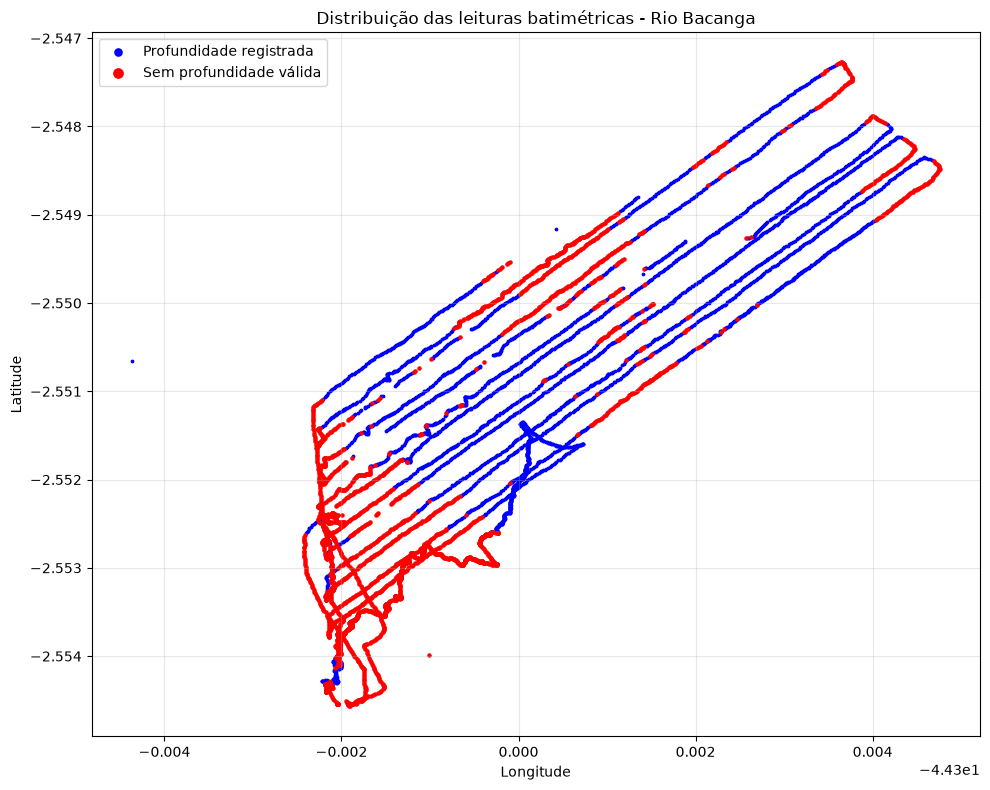

In [10]:

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Abrir os registros originais
with sqlite3.connect("Bacanga_bat_29-09-26.db") as conn:
    dados = pd.read_sql_query(
        "SELECT timestamp, gpgga, sddb FROM echomap_data",
        conn
    )

# Extrair coordenadas das sentenças GPS
def extrair_coordenadas(sentenca):
    try:
        partes = sentenca.split(",")
        if not partes[0].endswith("GGA"):
            return (float("nan"), float("nan"))

        def converter(valor, hemisferio):
            numero = float(valor)
            graus = int(numero // 100)
            minutos = numero - graus * 100
            decimal = graus + minutos / 60
            return -decimal if hemisferio in ("S", "W") else decimal

        lat = converter(partes[2], partes[3])
        lon = converter(partes[4], partes[5])
        return (lat, lon)
    except (ValueError, IndexError, TypeError, AttributeError):
        return (float("nan"), float("nan"))

def profundidade_original(sentenca):
    try:
        partes = sentenca.split(",")
        if not partes[0].endswith("DBT"):
            return float("nan")
        valor = float(partes[3])
        return valor if valor > 0 else float("nan")
    except (ValueError, IndexError, TypeError, AttributeError):
        return float("nan")

dados[["lat", "lon"]] = pd.DataFrame(
    dados["gpgga"].apply(extrair_coordenadas).tolist(),
    index=dados.index
)

dados["profundidade_original"] = dados["sddb"].apply(
    profundidade_original
)

dados = dados.dropna(subset=["lat", "lon"]).copy()

validos = dados[dados["profundidade_original"].notna()]
ausentes = dados[dados["profundidade_original"].isna()]

print("Registros com coordenadas:", len(dados))
print("Com profundidade válida:", len(validos))
print("Sem profundidade válida:", len(ausentes))

plt.figure(figsize=(10, 8))

plt.scatter(
    validos["lon"], validos["lat"],
    s=3, color="blue", label="Profundidade registrada"
)

plt.scatter(
    ausentes["lon"], ausentes["lat"],
    s=5, color="red", label="Sem profundidade válida"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Distribuição das leituras batimétricas - Rio Bacanga")
plt.legend(markerscale=3)
plt.grid(alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()


In [11]:

# Selecionar somente as leituras acústicas válidas
pontos_validos = dados.dropna(
    subset=["lat", "lon", "profundidade_original"]
).copy()

# Aplicar a correção de 20 cm do transdutor
pontos_validos["profundidade_corrigida"] = (
    pontos_validos["profundidade_original"] + 0.20
)

# Exportar sem alterar os arquivos anteriores
arquivo = "bacanga_somente_medicoes_validas.csv"

pontos_validos[
    ["lon", "lat", "profundidade_corrigida"]
].to_csv(arquivo, index=False, header=["X", "Y", "Z"])

print("Arquivo criado:", arquivo)
print("Quantidade de pontos:", len(pontos_validos))
print(
    "Menor profundidade corrigida:",
    pontos_validos["profundidade_corrigida"].min()
)
print(
    "Maior profundidade corrigida:",
    pontos_validos["profundidade_corrigida"].max()
)


Arquivo criado: bacanga_somente_medicoes_validas.csv
Quantidade de pontos: 3806
Menor profundidade corrigida: 0.43000000000000005
Maior profundidade corrigida: 6.11


In [2]:
import sqlite3
import pandas as pd
import numpy as np

# 1. Conectar ao banco de dados SQLite
db_path = 'Bacanga_bat_29-09-26.db'
conn = sqlite3.connect(db_path)

# 2. Ler a tabela echomap_data onde os dados brutos estão salvos
# Mudamos de sddpt para sddb para pegar a sentença SDDBT
query = 'SELECT timestamp, gpgga, sddb FROM echomap_data'
df_raw = pd.read_sql_query(query, conn)

print(f"Total de registros carregados: {len(df_raw)}")
df_raw.head()

Total de registros carregados: 7054


,timestamp,gpgga,sddb
0,2026-09-29 13:08:06,"$GPGGA,160806,0233.2636,S,04418.1299,W,1,11,0....","$SDDBT,,f,,M,,F*28"
1,2026-09-29 13:08:08,"$GPGGA,160808,0233.2637,S,04418.1300,W,1,11,0....","$SDDBT,,f,,M,,F*28"
2,2026-09-29 13:08:10,"$GPGGA,160810,0233.2638,S,04418.1300,W,1,11,0....","$SDDBT,,f,,M,,F*28"
3,2026-09-29 13:08:12,"$GPGGA,160812,0233.2638,S,04418.1300,W,1,11,0....","$SDDBT,,f,,M,,F*28"
4,2026-09-29 13:08:14,"$GPGGA,160814,0233.2638,S,04418.1301,W,1,11,0....","$SDDBT,,f,,M,,F*28"


## Decodificando as Sentenças NMEA

* **`$GPGGA`**: Contém dados de posicionamento.
* **`$SDDBT`**: Contém a leitura de profundidade direta do transdutor.
  - Exemplo: `$SDDBT,9.87,f,3.01,M,1.65,F*30`
  - O valor em metros está na quarta posição (índice 3 após o split). Caso esteja vazio, retornaremos 0.50.

**Offset do Barco:** Um offset de +20cm (0.20m) será somado a TODAS as leituras para compensar o calado do barco.

In [5]:
def parse_nmea_lat_lon(gpgga_str):
    '''Extrai Latitude e Longitude de uma string $GPGGA'''
    try:
        if not gpgga_str or not isinstance(gpgga_str, str) or not gpgga_str.startswith('$GPGGA'):
            return np.nan, np.nan
        
        parts = gpgga_str.split(',')
        if len(parts) < 6 or not parts[2] or not parts[4]:
            return np.nan, np.nan
        
        # Latitude: DDMM.MMMM
        lat_str = parts[2]
        lat_deg = float(lat_str[:2])
        lat_min = float(lat_str[2:])
        lat = lat_deg + (lat_min / 60.0)
        if parts[3] == 'S': lat = -lat
        
        # Longitude: DDDMM.MMMM
        lon_str = parts[4]
        lon_deg = float(lon_str[:3])
        lon_min = float(lon_str[3:])
        lon = lon_deg + (lon_min / 60.0)
        if parts[5] == 'W': lon = -lon
            
        return lat, lon
    except Exception:
        return np.nan, np.nan

def parse_nmea_sddbt(sddbt_str):
    '''Extrai Profundidade de uma string $SDDBT. Se nulo, retorna 0.50'''
    try:
        if not sddbt_str or not isinstance(sddbt_str, str) or not sddbt_str.startswith('$SDDBT'):
            return 0.50
        
        parts = sddbt_str.split(',')
        # Formato: $SDDBT, pés, f, metros, M, braças, F*XX
        if len(parts) < 5 or not parts[3]:
            return 0.50
            
        return float(parts[3])
    except Exception:
        return 0.50

# Testando as funções:
print('Teste GPGGA válido:', parse_nmea_lat_lon('$GPGGA,160932,0233.2639,S,04418.1302,W,1,10,0.84,19.46,M,-21.09,M,,*67'))
print('Teste SDDBT válido:', parse_nmea_sddbt('$SDDBT,9.87,f,3.01,M,1.65,F*30'))
print('Teste SDDBT raso/nulo:', parse_nmea_sddbt('$SDDBT,,f,,M,,F*28'))

Teste GPGGA válido: (-2.5543983333333333, -44.30217)
Teste SDDBT válido: 3.01
Teste SDDBT raso/nulo: 0.5


## Aplicando as Funções ao DataFrame

Aplicaremos as funções. Pontos sem coordenadas (lat/lon) ainda precisam ser descartados (pois não podemos plotá-los). No entanto, pontos sem profundidade não serão descartados, pois nossa função de profundidade já garantiu o valor de `0.50`.

In [ ]:
# Extraindo lat e lon
df_raw[['lat', 'lon']] = df_raw['gpgga'].apply(lambda x: pd.Series(parse_nmea_lat_lon(x)))

# Extraindo depth usando a nova função do SDDBT
df_raw['depth'] = df_raw['sddb'].apply(parse_nmea_sddbt)

# Aplicando offset do transdutor (+20cm)
df_raw['depth'] = df_raw['depth'] + 0.20

# Filtrando APENAS coordenadas inválidas. Pontos muito rasos foram salvos com depth=0.5
df_clean = df_raw.dropna(subset=['lat', 'lon']).copy()

print(f"Registros válidos (com coordenadas): {len(df_clean)}")
print(f"Desse total, {(df_clean['depth'] == 0.7).sum()} foram substituídos por 0.70m (0.50 raso + 0.20 calado)")
df_clean[['timestamp', 'lat', 'lon', 'depth']].head(10)

Registros válidos (com coordenadas): 7051
Desse total, 3256 foram substituídos por 0.70m (0.50 raso + 0.20 calado)


,timestamp,lat,lon,depth
0,2026-09-29 13:08:06,-2.554393,-44.302165,0.7
1,2026-09-29 13:08:08,-2.554395,-44.302167,0.7
2,2026-09-29 13:08:10,-2.554397,-44.302167,0.7
3,2026-09-29 13:08:12,-2.554397,-44.302167,0.7
4,2026-09-29 13:08:14,-2.554397,-44.302168,0.7
5,2026-09-29 13:08:16,-2.554397,-44.302170,0.7
6,2026-09-29 13:08:18,-2.554397,-44.302170,0.7
7,2026-09-29 13:08:20,-2.554397,-44.302170,0.7
8,2026-09-29 13:08:22,-2.554398,-44.302170,0.7
9,2026-09-29 13:08:24,-2.554398,-44.302170,0.7


## Salvando os Dados (Formato XYZ e Nova Tabela)

In [ ]:
# 1. Salvar no banco de dados em uma tabela limpa
df_clean[['timestamp', 'lat', 'lon', 'depth']].to_sql('extracted_data_clean', conn, if_exists='replace', index=False)
print("Dados salvos com sucesso na tabela 'extracted_data_clean'!")
conn.close()

# 2. Salvar como CSV (formato xyz)
csv_path = 'bacanga_raw_xyz.csv'
df_clean[['lon', 'lat', 'depth']].to_csv(csv_path, index=False, header=['X', 'Y', 'Z'])
print(f"Dados salvos como arquivo CSV em: {csv_path}")

Dados salvos com sucesso na tabela 'extracted_data_clean'!
Dados salvos como arquivo CSV em: bacanga_raw_xyz.csv
